In [1]:
from datasets import load_dataset

print("Starting dataset loading...")

ds = load_dataset(
    "vasu1111/customer-support-tickets"
)

print("Dataset loaded successfully!")

Starting dataset loading...


Dataset loaded successfully!


# Check dataset information

In [2]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8'],
        num_rows: 61765
    })
})


# Access the training dataset

In [3]:
data = ds['train']

print('Total records in the dataset:', len(data))

print('Column Names:', data.column_names)

Total records in the dataset: 61765
Column Names: ['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']


# Convert into Pandas DataFrame

In [4]:
import pandas as pd
import numpy as np

df = data.to_pandas()

print(df.head(2))

                           subject  \
0  Wesentlicher Sicherheitsvorfall   
1               Account Disruption   

                                                body  \
0  Sehr geehrtes Support-Team,\n\nich möchte eine...   
1  Dear Customer Support Team,\n\nI am writing to...   

                                              answer      type  \
0  Vielen Dank für die Meldung des kritischen Sic...  Incident   
1  Thank you for reaching out, <name>. We are awa...  Incident   

               queue priority language  version     tag_1       tag_2  \
0  Technical Support     high       de     51.0  Security      Outage   
1  Technical Support     high       en     51.0   Account  Disruption   

        tag_3        tag_4         tag_5 tag_6 tag_7 tag_8  
0  Disruption  Data Breach          None  None  None  None  
1      Outage           IT  Tech Support  None  None  None  


# Understand the dataset

In [5]:
print('Dataset Shape:', df.shape)

Dataset Shape: (61765, 16)


In [6]:
df.columns

Index(['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language',
       'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6',
       'tag_7', 'tag_8'],
      dtype='object')

In [7]:
df.dtypes

subject      object
body         object
answer       object
type         object
queue        object
priority     object
language     object
version     float64
tag_1        object
tag_2        object
tag_3        object
tag_4        object
tag_5        object
tag_6        object
tag_7        object
tag_8        object
dtype: object

In [8]:
df.isnull().sum()

subject      5299
body            2
answer      13189
type        13178
queue           0
priority        0
language        0
version     33178
tag_1       13178
tag_2       13237
tag_3       13409
tag_4       17775
tag_5       34129
tag_6       48540
tag_7       55797
tag_8       59293
dtype: int64

In [9]:
print("Total Rows:", df.shape[0])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Total Rows: 61765

Missing Values:
subject      5299
body            2
answer      13189
type        13178
queue           0
priority        0
language        0
version     33178
tag_1       13178
tag_2       13237
tag_3       13409
tag_4       17775
tag_5       34129
tag_6       48540
tag_7       55797
tag_8       59293
dtype: int64

Total Missing Values:
320204


In [10]:
# Handling Missing Values

# Create a copy to preserve original data
df = df.copy()

# Replace missing subject values with empty strings
df["subject"] = df["subject"].fillna("")

# Remove rows where body is missing(2 rows has to remove)
df = df.dropna(subset=["body"])

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape after cleaning: (61763, 16)

Missing values:
subject         0
body            0
answer      13189
type        13178
queue           0
priority        0
language        0
version     33176
tag_1       13178
tag_2       13237
tag_3       13409
tag_4       17775
tag_5       34129
tag_6       48540
tag_7       55796
tag_8       59292
dtype: int64


### 
subject: A subject is helpful but not mandatory. We can still classify a ticket using its body.



body: We need the customer's message. Since only 2 records are missing, we will remove them.



answer, type, version, and tag_1 to tag_8: These are not required for our initial model, so we leave their missing values untouched.

In [11]:
# Combine subject and body into a single text column

df["text"] = (
    df["subject"].astype(str)
    + " "
    + df["body"].astype(str)
)

print(df[["subject", "body", "text", "queue"]].head())

                                             subject  \
0                    Wesentlicher Sicherheitsvorfall   
1                                 Account Disruption   
2  Query About Smart Home System Integration Feat...   
3                  Inquiry Regarding Invoice Details   
4  Question About Marketing Agency Software Compa...   

                                                body  \
0  Sehr geehrtes Support-Team,\n\nich möchte eine...   
1  Dear Customer Support Team,\n\nI am writing to...   
2  Dear Customer Support Team,\n\nI hope this mes...   
3  Dear Customer Support Team,\n\nI hope this mes...   
4  Dear Support Team,\n\nI hope this message reac...   

                                                text                  queue  
0  Wesentlicher Sicherheitsvorfall Sehr geehrtes ...      Technical Support  
1  Account Disruption Dear Customer Support Team,...      Technical Support  
2  Query About Smart Home System Integration Feat...  Returns and Exchanges  
3  Inquiry Reg

In [12]:
# Remove empty messages

df["text"] = df["text"].str.strip()
df['text']

0        Wesentlicher Sicherheitsvorfall Sehr geehrtes ...
1        Account Disruption Dear Customer Support Team,...
2        Query About Smart Home System Integration Feat...
3        Inquiry Regarding Invoice Details Dear Custome...
4        Question About Marketing Agency Software Compa...
                               ...                        
61760    Assistance Needed for IFTTT Docker Integration...
61761    Bitten um Unterstützung bei der Integration Se...
61762    Hello Customer Support, I am inquiring about t...
61763    Hilfe bei digitalen Strategie-Problemen Die Qu...
61764    Optimierung Ihrer Datenanalyse-Plattform erlei...
Name: text, Length: 61763, dtype: object

In [13]:
df = df[df["text"] != ""].copy()

print("Final dataset shape:", df.shape)

Final dataset shape: (61763, 17)


In [14]:
# Verify missing values in required columns

print("Subject missing:", df["subject"].isnull().sum())

print("Body missing:", df["body"].isnull().sum())

print("Queue missing:", df["queue"].isnull().sum())

print("Text missing:", df["text"].isnull().sum())

Subject missing: 0
Body missing: 0
Queue missing: 0
Text missing: 0


In [15]:
# Check your final dataset

print("Final Rows:", df.shape[0])

print("\nTarget Categories:")
print(df["queue"].value_counts())

print("\nSample Customer Tickets:")
print(df[["text", "queue"]].head(10))

Final Rows: 61763

Target Categories:
queue
Technical Support                         14186
Product Support                            8958
Customer Service                           7420
IT Support                                 5725
Billing and Payments                       4874
Returns and Exchanges                      2438
Service Outages and Maintenance            1912
Sales and Pre-Sales                        1490
Human Resources                             914
General Inquiry                             668
Pets & Animals/Pet Services                 386
News                                        383
IT & Technology/Security Operations         365
Autos & Vehicles/Sales                      364
Health/Medical Services                     362
Home & Garden/Home Improvement              361
Pets & Animals/Veterinary Care              356
Health/Mental Health                        347
Business & Industrial/Manufacturing         346
Online Communities/Forums                   

###

"I first analyzed missing values using Pandas isnull().sum(). I found missing values in subject, body, answer, type, version, and ticket tags. Since my objective was to classify customer support tickets based on their messages, I filled missing subject values with empty strings, removed records with missing customer message bodies, and retained other columns with missing values because they were not required for the initial classification model."

# Display sample customer tickets

In [16]:
for i in range(5):

    print("\nSubject:", df["subject"].iloc[i])

    print("Customer Message:")
    print(df["body"].iloc[i])

    print("Queue:")
    print(df["queue"].iloc[i])

    print("-" * 50)


Subject: Wesentlicher Sicherheitsvorfall
Customer Message:
Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komponenten unserer Infrastruktur betrifft. Betroffene Geräte umfassen Projektoren, Bildschirme und Speicherlösungen auf Cloud-Plattformen. Der Grund für die Annahme ist, dass der Vorfall eine potenzielle Datenverletzung im Zusammenhang mit einer Cyberattacke darstellt, was ein erhebliches Risiko für sensible Informationen und den laufenden Geschäftsbetrieb unserer Organisation bedeutet.\n\nUnsere initialen Untersuchungen haben ungewöhnliche Aktivitäten und Abweichungen bei den Geräten ergeben. Trotz der Umsetzung unserer standardisierten Behebungs- und Eindämmungsmaßnahmen konnte die Bedrohung bislang nicht vollständig eliminiert.
Queue:
Technical Support
--------------------------------------------------

Subject: Account Disruption
Customer Message:
Dear Customer Support Team,\n\nI am writing to report a significa

### We are examining the actual customer messages and their corresponding department labels.

# Exploratory Data Analysis (EDA)


In [17]:
print(df["queue"].value_counts())

queue
Technical Support                         14186
Product Support                            8958
Customer Service                           7420
IT Support                                 5725
Billing and Payments                       4874
Returns and Exchanges                      2438
Service Outages and Maintenance            1912
Sales and Pre-Sales                        1490
Human Resources                             914
General Inquiry                             668
Pets & Animals/Pet Services                 386
News                                        383
IT & Technology/Security Operations         365
Autos & Vehicles/Sales                      364
Health/Medical Services                     362
Home & Garden/Home Improvement              361
Pets & Animals/Veterinary Care              356
Health/Mental Health                        347
Business & Industrial/Manufacturing         346
Online Communities/Forums                   343
Shopping/E-commerce               

#### This displays how many tickets belong to each department.

# Visualize ticket categories

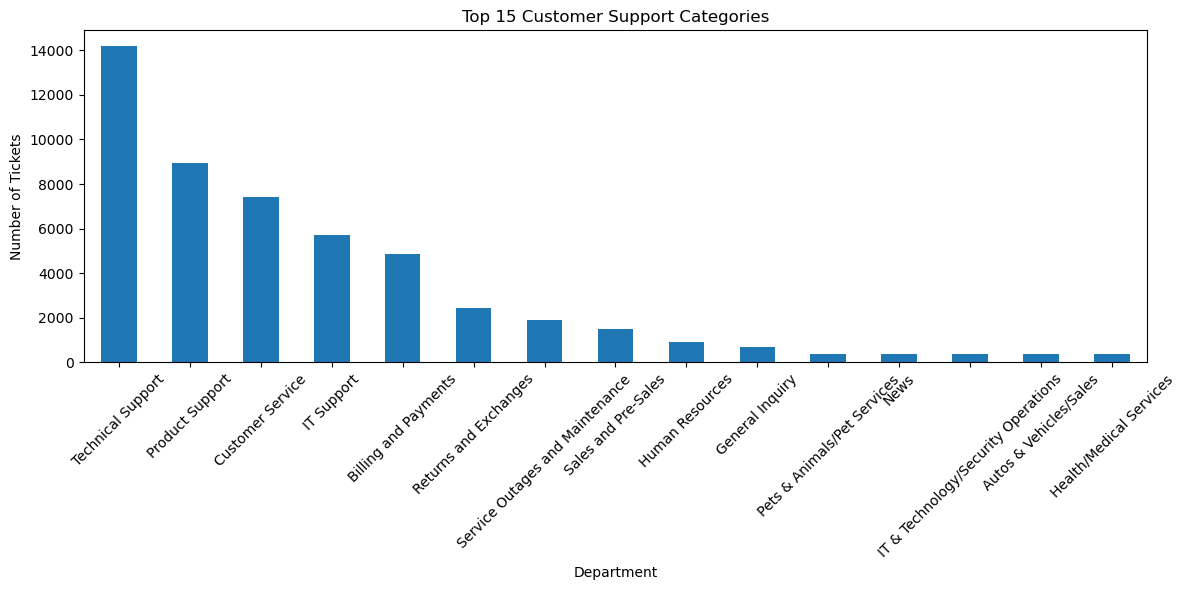

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

df["queue"].value_counts().head(15).plot(
    kind="bar"
)

plt.title("Top 15 Customer Support Categories")
plt.xlabel("Department")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
print(df["language"].value_counts())

language
de    33503
en    28260
Name: count, dtype: int64


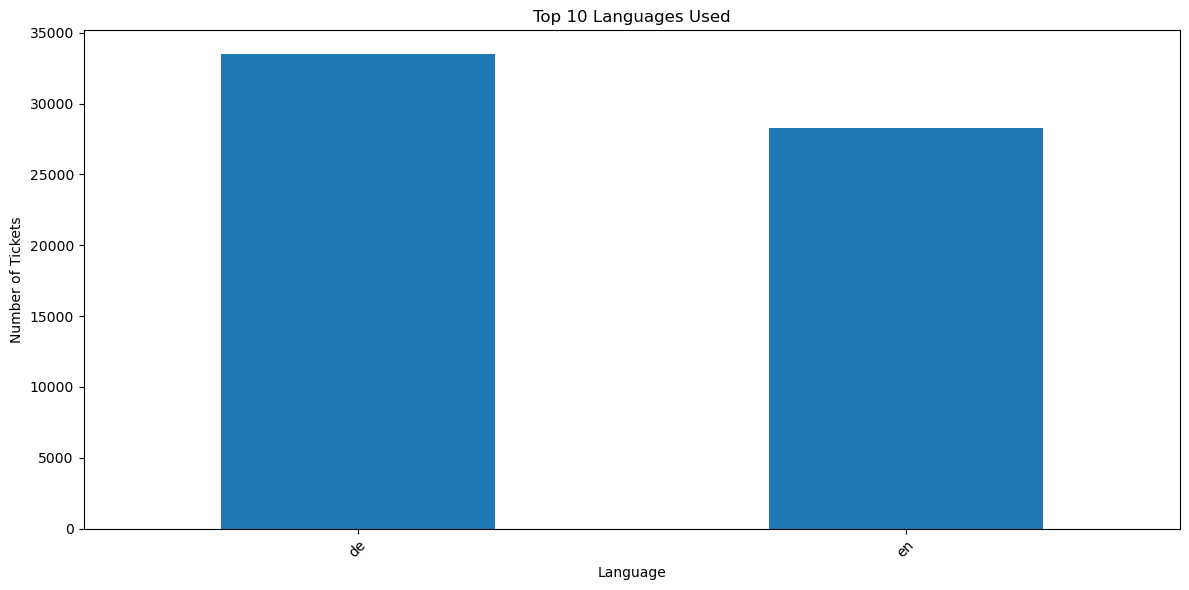

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

df["language"].value_counts().head(10).plot(
    kind="bar"
)

plt.title("Top 10 Languages Used")
plt.xlabel("Language")
plt.ylabel("Number of Tickets")

plt.ylabel("Number of Tickets")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
df = df[df["language"] == "en"].copy()

print("English tickets:", len(df))

English tickets: 28260


# Text Preprocessing

In [22]:
import re

def preprocess_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [23]:
df['clean_text'] = df['text'].apply(preprocess_text)

print(df[['text', 'clean_text']].head())

                                                text  \
1  Account Disruption Dear Customer Support Team,...   
2  Query About Smart Home System Integration Feat...   
3  Inquiry Regarding Invoice Details Dear Custome...   
4  Question About Marketing Agency Software Compa...   
5  Feature Query Dear Customer Support,\n\nI hope...   

                                          clean_text  
1  account disruption dear customer support team ...  
2  query about smart home system integration feat...  
3  inquiry regarding invoice details dear custome...  
4  question about marketing agency software compa...  
5  feature query dear customer support n ni hope ...  


In [25]:
print(df[['text', 'clean_text']][0:1])

                                                text  \
1  Account Disruption Dear Customer Support Team,...   

                                          clean_text  
1  account disruption dear customer support team ...  


# Convert text into numerical features using TF-IDF

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['clean_text']
y = df['queue']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (28260,)
Target: (28260,)


In [28]:
y.value_counts()

queue
Technical Support                  8149
Product Support                    5304
Customer Service                   4269
IT Support                         3333
Billing and Payments               2897
Returns and Exchanges              1402
Service Outages and Maintenance    1106
Sales and Pre-Sales                 843
Human Resources                     553
General Inquiry                     404
Name: count, dtype: int64

In [29]:
# Remove very rare categories 

class_counts = y.value_counts()

valid_classes = class_counts[class_counts >= 2].index

df = df[df["queue"].isin(valid_classes)].copy()

X = df["clean_text"]
y = df["queue"]

print("Number of categories:", y.nunique())
print(y.value_counts())

Number of categories: 10
queue
Technical Support                  8149
Product Support                    5304
Customer Service                   4269
IT Support                         3333
Billing and Payments               2897
Returns and Exchanges              1402
Service Outages and Maintenance    1106
Sales and Pre-Sales                 843
Human Resources                     553
General Inquiry                     404
Name: count, dtype: int64


# Train-Test Split

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 22608
Testing records: 5652


# Build ML Models

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

In [32]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC()
}

models

{'Logistic Regression': LogisticRegression(max_iter=1000),
 'Naive Bayes': MultinomialNB(),
 'Linear SVM': LinearSVC()}

In [33]:
from sklearn.metrics import accuracy_score

results = {}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),

        ("classifier", model)
    ])

    print("Training:", name)

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    trained_models[name] = pipeline

    print("Accuracy:", accuracy)

    print("-" * 40)

Training: Logistic Regression
Accuracy: 0.5858103326256192
----------------------------------------
Training: Naive Bayes
Accuracy: 0.4164897381457891
----------------------------------------
Training: Linear SVM
Accuracy: 0.7250530785562632
----------------------------------------


In [34]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

print(results_df.sort_values(
    by="Accuracy",
    ascending=False
))

                 Model  Accuracy
2           Linear SVM  0.725053
0  Logistic Regression  0.585810
1          Naive Bayes  0.416490


# Model Evaluation

In [35]:
from sklearn.metrics import classification_report

best_model_name = max(results, key=results.get)

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Best Model: Linear SVM
                                 precision    recall  f1-score   support

           Billing and Payments       0.92      0.85      0.89       579
               Customer Service       0.73      0.67      0.70       854
                General Inquiry       0.91      0.51      0.65        81
                Human Resources       0.95      0.62      0.75       111
                     IT Support       0.69      0.62      0.66       666
                Product Support       0.68      0.71      0.69      1061
          Returns and Exchanges       0.83      0.62      0.71       280
            Sales and Pre-Sales       0.82      0.60      0.69       169
Service Outages and Maintenance       0.89      0.71      0.79       221
              Technical Support       0.66      0.81      0.73      1630

                       accuracy                           0.73      5652
                      macro avg       0.81      0.67      0.73      5652
                   weighte

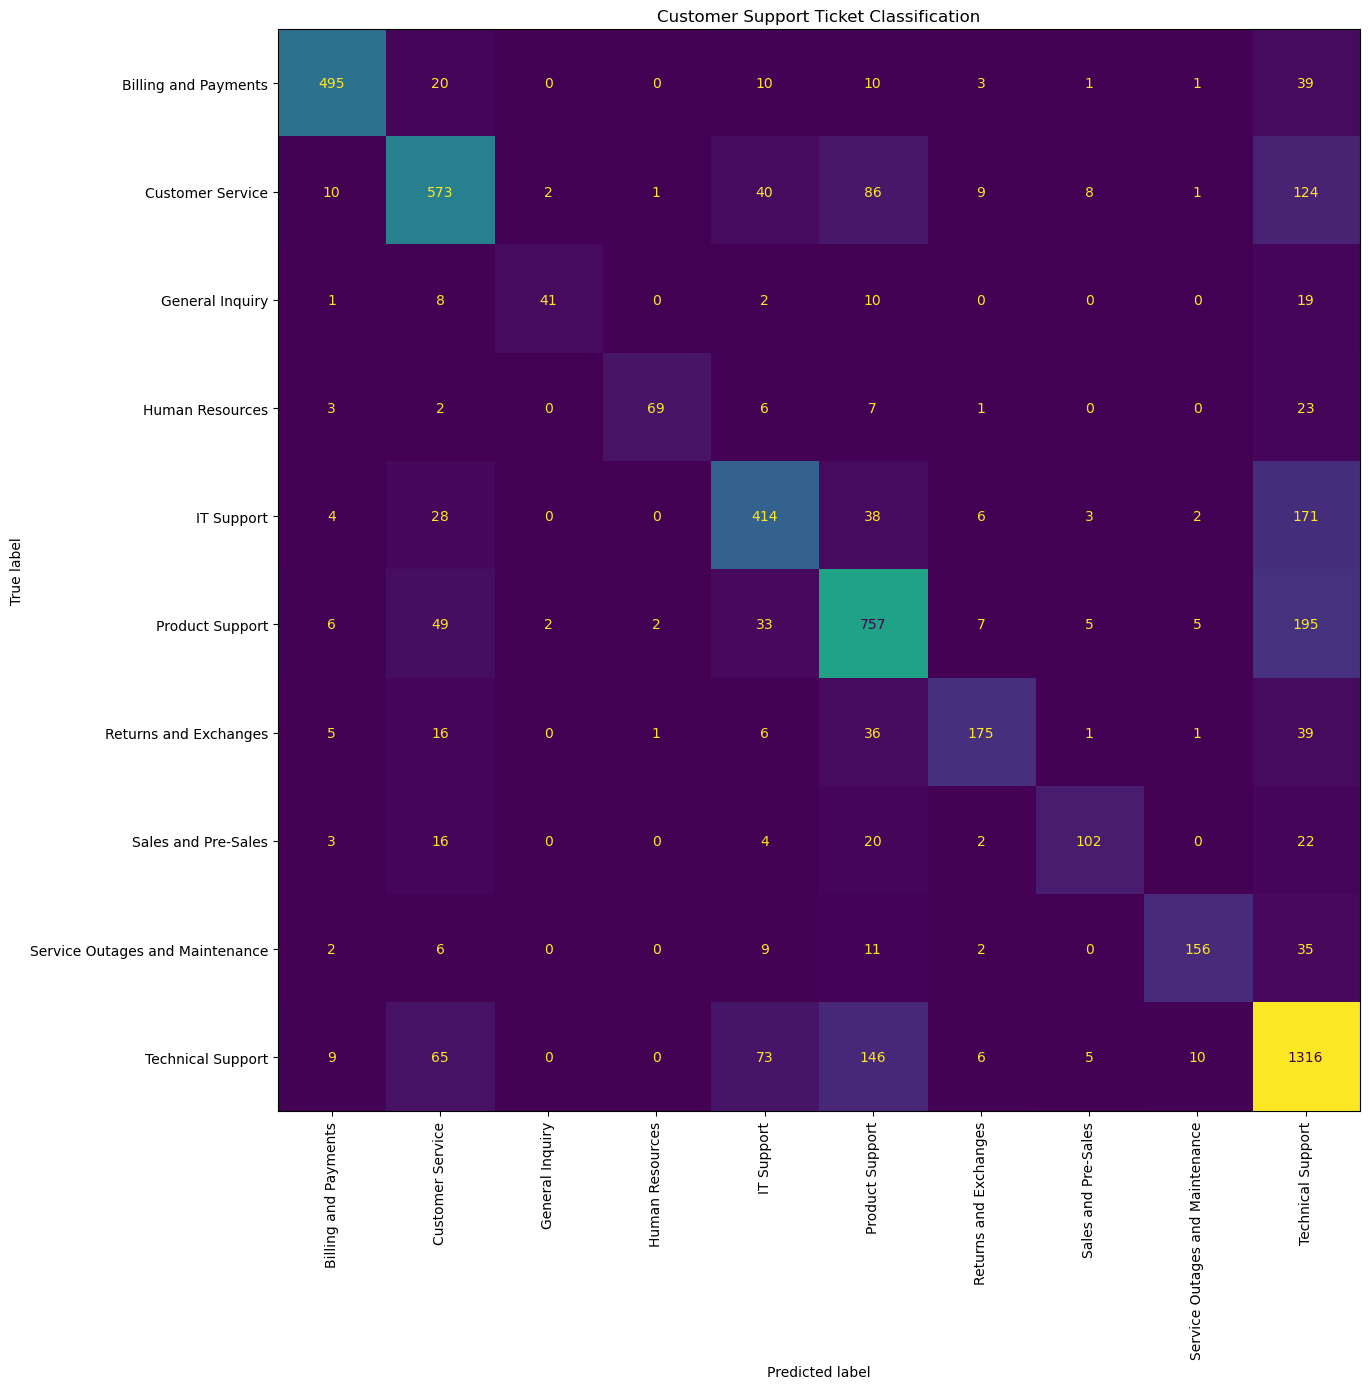

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(14, 14))

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("Customer Support Ticket Classification")
plt.tight_layout()
plt.show()

# Save your trained model

In [38]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/customer_support_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


# Test with new customer messages

In [39]:
sample_tickets = [

    "I cannot login to my account",

    "My payment was deducted twice",

    "I want to return my purchased product",

    "I am unable to access the website",

    "I need help with my subscription"
]

for ticket in sample_tickets:

    prediction = best_model.predict([ticket])

    print("Customer Ticket:", ticket)

    print("Predicted Department:", prediction[0])

    print("-" * 50)

Customer Ticket: I cannot login to my account
Predicted Department: Billing and Payments
--------------------------------------------------
Customer Ticket: My payment was deducted twice
Predicted Department: Billing and Payments
--------------------------------------------------
Customer Ticket: I want to return my purchased product
Predicted Department: Returns and Exchanges
--------------------------------------------------
Customer Ticket: I am unable to access the website
Predicted Department: IT Support
--------------------------------------------------
Customer Ticket: I need help with my subscription
Predicted Department: IT Support
--------------------------------------------------
